## 1. Setup: imports, paths, settings and plot style

In [2]:
# Initial imports
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

# Get the parent directory 
project_root = Path().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
# Import custom modules
import Scripts.sql_server_connect as sql
import Scripts.python_cleaning as clean

QUERIES_DIR = project_root / "Queries" / "SQL Business queries"
ASSETS_DIR = project_root / "Assets"
ASSETS_DIR.mkdir(exist_ok=True)

# Database settings
# Set OLIST_SERVER and OLIST_DATABASE as environment variables to override these defaults.
SERVER = os.getenv("OLIST_SERVER", r"localhost\SQLEXPRESS")
DATABASE = os.getenv("OLIST_DATABASE", "OlistDB")

# Column names returned by the SQL files (change here if you rename them in SQL)
CAT_NAME_COL = "category_name"
GMV_COL = "gross_merchandise_value"   
AOV_COL = "average_order_value"
ORDERS_COL = "order_count"

TARGET = "Health & Beauty"

# Colours
OLIST_COLORS = {
    "primary_blue": "#3951db",
    "dark_navy": "#131b31",
    "coral_orange": "#d45d37",
    "gold": "#dfa344",
    "sage_green": "#88a86a",
    "mauve": "#d2abc2",
}

# Plot style: set once, applies to every chart below
plt.rcParams.update({
    "figure.figsize": (15, 5),
    "figure.facecolor": "white",
    "font.size": 11,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.titlepad": 15,
    "axes.titlecolor": OLIST_COLORS["gold"],
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "xtick.labelsize": 11,
    "xtick.color": OLIST_COLORS["gold"],
    "ytick.color": OLIST_COLORS["gold"],
    "legend.frameon": False,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.transparent": True,
})



Part 1: Category Sales Analysis for period 06.2017-06.2018
Targeted Category: Health And Beauty

In [3]:
# Connecting to MSSQL Server database
engine = sql.mssql_engine(SERVER, DATABASE)

Loading General Category Information

In [3]:
print("Data returned from Microsoft SQL Server:")
df_category_revenue = sql.load_sql_to_df(str(QUERIES_DIR/"SQL Revenue by Category.sql"), engine)
df_category_revenue = clean.clean_category_names(df_category_revenue, CAT_NAME_COL, {"Health Beauty": "Health & Beauty"})


# Filter Health & Beauty Category
hb_row =  df_category_revenue[df_category_revenue[CAT_NAME_COL] == TARGET]
if hb_row.empty:
    raise ValueError(f"'{TARGET}' not found. Categories: {df_category_revenue[CAT_NAME_COL].tolist()[:10]}...")

df_category_revenue.head(5)

Data returned from Microsoft SQL Server:


,category_name,category_count,gross_merchandise_value,gross_order_value,gross_freight_cost
0,Watches Gifts,4816,928731.94,1009303.76,80571.82
1,Health & Beauty,7117,915675.02,1049522.67,133847.65
2,Bed Bath Table,8238,764200.49,915548.31,151347.82
3,Sports Leisure,6378,725880.66,848627.37,122746.71
4,Computers Accessories,5900,667198.15,779591.61,112393.46


Saved: C:\Dev\EdmondAnt\OLIST_SQL_Challenge\Assets\top10.png


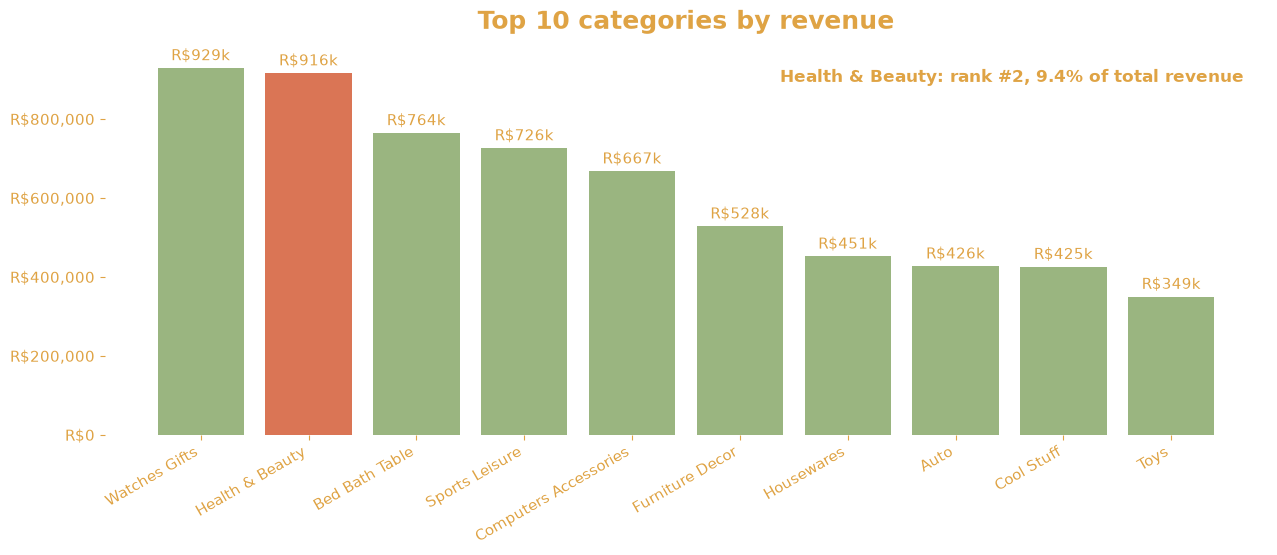

In [46]:
hb_rank = hb_row.index[0] + 1
hb_share = hb_row[GMV_COL].iloc[0] / df_category_revenue[GMV_COL].sum() * 100

top10 = df_category_revenue.head(10)
bar_colors = [
    OLIST_COLORS["coral_orange"] if name == TARGET else OLIST_COLORS["sage_green"]
    for name in top10[CAT_NAME_COL]
]

fig, ax = plt.subplots()
bars = ax.bar(top10[CAT_NAME_COL], top10[GMV_COL], color=bar_colors, alpha=0.85)
ax.bar_label(bars, labels=[f"R${v / 1000:,.0f}k" for v in top10[GMV_COL]], padding=3, color = OLIST_COLORS["gold"])
ax.yaxis.set_major_formatter("R${x:,.0f}")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_title("Top 10 categories by revenue")
ax.text(
    0.98, 0.95,
    f"{TARGET}: rank #{hb_rank}, {hb_share:.1f}% of total revenue",
    transform=ax.transAxes, ha="right", va="top",
    fontsize=12, fontweight="bold", color = OLIST_COLORS["gold"],
)

clean.save_chart(fig, ASSETS_DIR/"top10.png")
plt.show()

Health and Beaty revenue by month

Saved: C:\Dev\EdmondAnt\OLIST_Ecommerce_Sales_Analysis\Assets\hb_monthly_rev.png


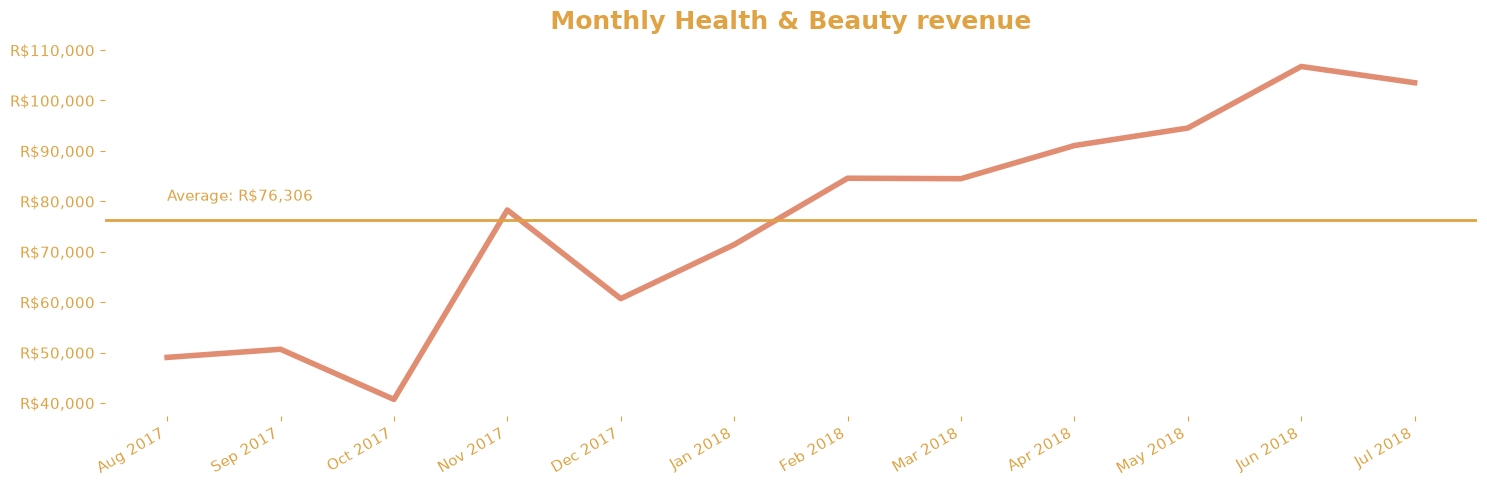

In [4]:
df_month = sql.load_sql_to_df(str(QUERIES_DIR/"SQL Revenue by Month.sql"), engine)
df_month = clean.clean_category_names(df_month, CAT_NAME_COL, {"Health Beauty": "Health & Beauty"})
df_hb = df_month[df_month[CAT_NAME_COL] == TARGET]


avg_revenue = df_hb[GMV_COL].mean()

fig, ax = plt.subplots()
x = clean.style_month_axis(ax, df_hb["order_period"])
ax.plot(x, df_hb[GMV_COL], color=OLIST_COLORS["coral_orange"], alpha=0.7, linewidth = 4)
ax.axhline(avg_revenue, color = OLIST_COLORS["gold"], linewidth=2)
ax.annotate(text=f"Average: R${avg_revenue:,.0f}", xy = (0, avg_revenue*1.05), color = OLIST_COLORS["gold"])
ax.yaxis.set_major_formatter("R${x:,.0f}")
ax.set_title(f"Monthly {TARGET} revenue")
fig.tight_layout()
clean.save_chart(fig, ASSETS_DIR/"hb_monthly_rev.png")
plt.show()

In [7]:
df_hb.head(12)

,order_period,category_name,gross_merchandise_value,average_order_value,average_item_price,order_count
465,2017-08-01,Health & Beauty,49030.23,145.059852,139.29,338
466,2017-09-01,Health & Beauty,50649.16,142.272921,134.71,356
467,2017-10-01,Health & Beauty,40698.99,126.394378,116.28,322
468,2017-11-01,Health & Beauty,78274.40,150.817726,136.60,519
469,2017-12-01,Health & Beauty,60688.75,142.461854,131.93,426
470,2018-01-01,Health & Beauty,71405.60,126.830550,115.36,563
471,2018-02-01,Health & Beauty,84576.55,142.145462,130.12,595
472,2018-03-01,Health & Beauty,84488.57,139.650528,128.79,605
473,2018-04-01,Health & Beauty,91058.45,147.105735,132.93,619
474,2018-05-01,Health & Beauty,94534.38,141.306995,125.88,669


Saved: C:\Dev\EdmondAnt\OLIST_Ecommerce_Sales_Analysis\Assets\hb_monthly_revenue.png


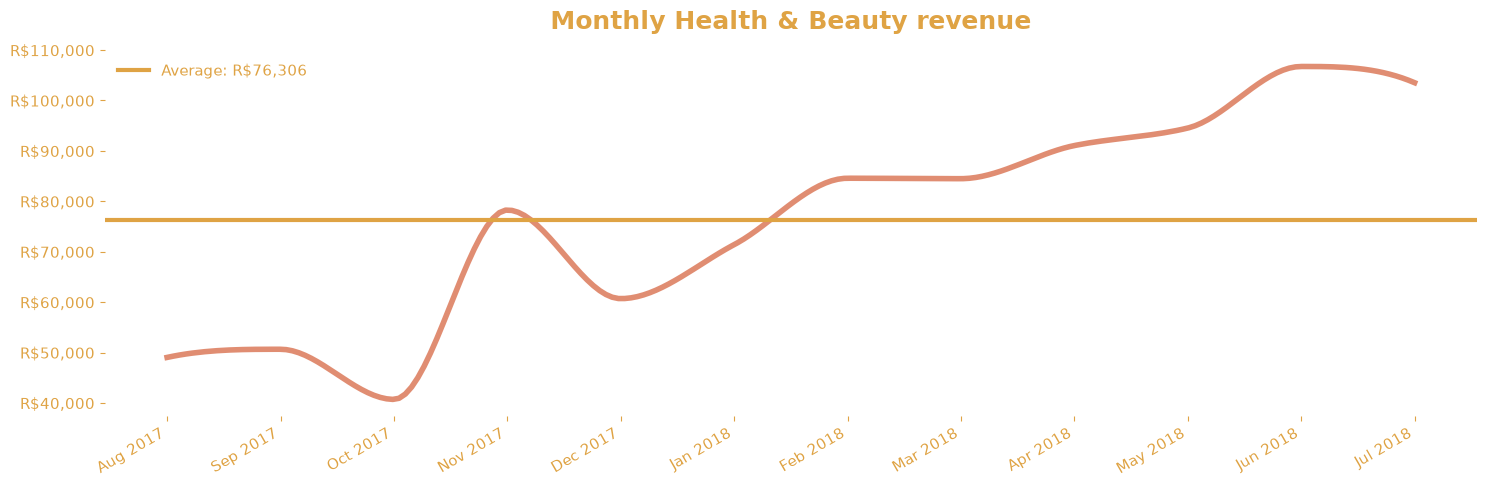

In [5]:
df_month = sql.load_sql_to_df(str(QUERIES_DIR/"SQL Revenue by Month.sql"), engine)
df_month = clean.clean_category_names(df_month, CAT_NAME_COL, {"Health Beauty": "Health & Beauty"})

df_hb = df_month[df_month[CAT_NAME_COL] == TARGET]

avg_revenue = df_hb[GMV_COL].mean()

fig, ax = plt.subplots()
x = clean.style_month_axis(ax, df_hb["order_period"])   # 0, 1, 2, ... month positions
y = df_hb[GMV_COL].to_numpy()

x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = PchipInterpolator(x, y)(x_smooth)             # fitted on x, the same scale as the plot
ax.plot(x_smooth, y_smooth, color=OLIST_COLORS["coral_orange"], alpha=0.7, linewidth=4)

ax.axhline(avg_revenue, color=OLIST_COLORS["gold"], linewidth=3,
           label=f"Average: R${avg_revenue:,.0f}")
ax.yaxis.set_major_formatter("R${x:,.0f}")
ax.set_title(f"Monthly {TARGET} revenue")
ax.legend(loc="upper left", labelcolor = OLIST_COLORS["gold"])
fig.tight_layout()
clean.save_chart(fig, ASSETS_DIR/"hb_monthly_revenue.png")
plt.show()

We calculate revenue as number of orders x order price. If revenue grew during this period, it means that either number of order or average order price or both grew during the given period. Let's find out where the growth occured.

Saved: C:\Dev\EdmondAnt\OLIST_Ecommerce_Sales_Analysis\Assets\hb_aov_and_orders.png


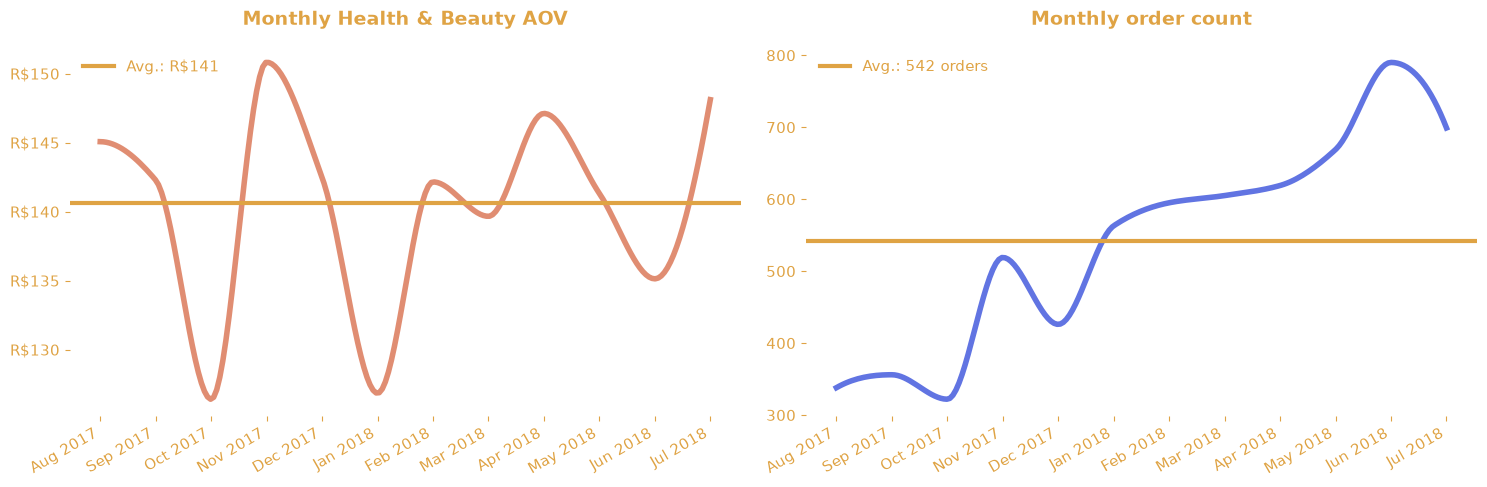

In [ ]:
avg_aov = df_hb[AOV_COL].mean()
avg_orders = df_hb[ORDERS_COL].mean()

fig, (ax1, ax2) = plt.subplots(1, 2)

# Average order value
x = clean.style_month_axis(ax1, df_hb["order_period"])
y = df_hb[AOV_COL].to_numpy()

x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = PchipInterpolator(x, y)(x_smooth)    


ax1.plot(x_smooth, y_smooth, color=OLIST_COLORS["coral_orange"], linewidth=4, alpha=0.7)
ax1.axhline(avg_aov, color = OLIST_COLORS["gold"], linewidth=3, label=f"Avg.: R${avg_aov:,.0f}")
ax1.yaxis.set_major_formatter("R${x:,.0f}")
ax1.set_title(f"Monthly {TARGET} AOV", fontsize=14)
ax1.legend(loc="upper left", labelcolor = OLIST_COLORS["gold"])

# Number of orders (a count, so no currency symbol)
x = clean.style_month_axis(ax2, df_hb["order_period"])
y = df_hb[ORDERS_COL].to_numpy()

x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = PchipInterpolator(x, y)(x_smooth)    

ax2.plot(x_smooth, y_smooth, color=OLIST_COLORS["primary_blue"], linewidth=4, alpha=0.8)
ax2.axhline(avg_orders, color = OLIST_COLORS["gold"], linewidth=3, label=f"Avg.: {avg_orders:,.0f} orders",
            mec = OLIST_COLORS["gold"])
ax2.yaxis.set_major_formatter("{x:,.0f}")
ax2.set_title("Monthly Order Count", fontsize=14)
ax2.legend(loc="upper left", labelcolor = OLIST_COLORS["gold"])


fig.tight_layout()
clean.save_chart(fig, ASSETS_DIR/"hb_aov_and_orders.png")
plt.show()

Saved: C:\Dev\EdmondAnt\OLIST_Ecommerce_Sales_Analysis\Assets\hb_seasonal_index.png


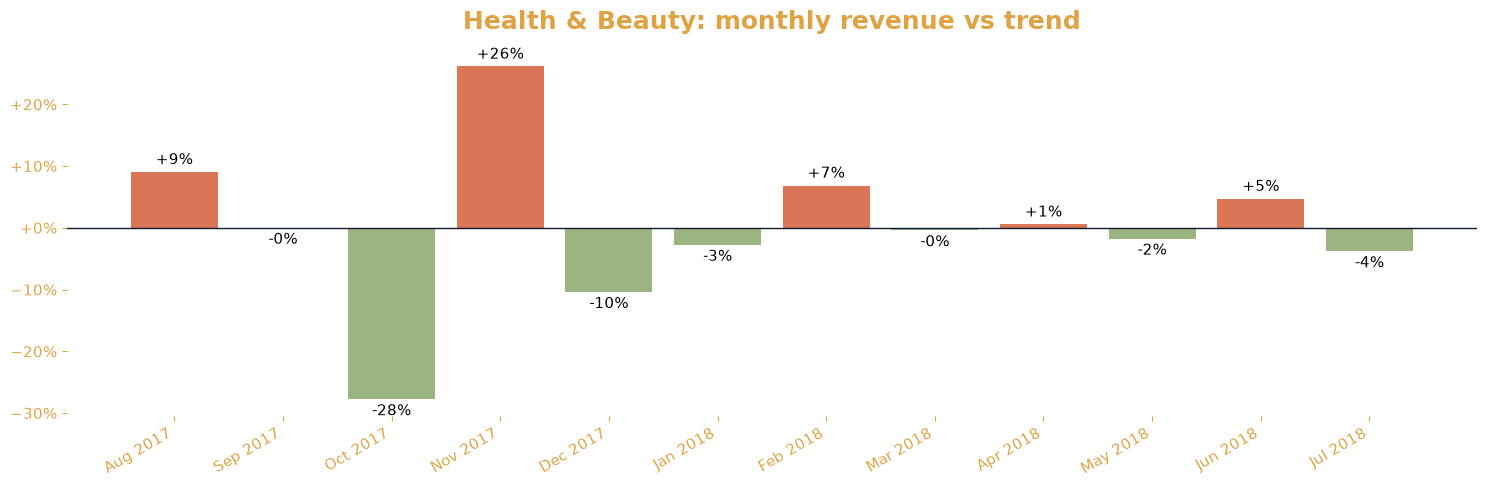

In [8]:
y = df_hb[GMV_COL].to_numpy()
x_pos = np.arange(len(y))
slope, intercept = np.polyfit(x_pos, y, 1)
trend = intercept + slope * x_pos
vs_trend_pct = (y / trend - 1) * 100            # +20 means 20% above trend
 
bar_colors = [OLIST_COLORS["coral_orange"] if v >= 0 else OLIST_COLORS["sage_green"] for v in vs_trend_pct]
 
fig, ax = plt.subplots()
x = clean.style_month_axis(ax, df_hb["order_period"])
bars = ax.bar(x, vs_trend_pct, color=bar_colors, alpha=0.85)
ax.bar_label(bars, labels=[f"{v:+.0f}%" for v in vs_trend_pct], padding=3)
ax.axhline(0, color=OLIST_COLORS["dark_navy"], linewidth=1)
ax.yaxis.set_major_formatter("{x:+.0f}%")
ax.set_title(f"{TARGET}: monthly revenue vs trend")
fig.tight_layout()
clean.save_chart(fig, ASSETS_DIR / "hb_seasonal_index.png")
plt.show()

In [10]:
table = df_hb.assign(
    Month=df_hb["order_period"].dt.strftime("%b %Y"),
    MoM_pct=df_hb[GMV_COL].pct_change() * 100,
    VsAverage_pct=(df_hb[GMV_COL] / df_hb[GMV_COL].mean() - 1) * 100,
    VsTrend_pct=vs_trend_pct,
)[["Month", GMV_COL, ORDERS_COL, AOV_COL, "MoM_pct", "VsAverage_pct", "VsTrend_pct"]]
table.columns = ["Month", "Revenue (R$)", "Orders", "AOV (R$)", "MoM %", "vs average %", "vs trend %"]

styled = (
    table.style
    .format({"Revenue (R$)": "{:,.0f}", "Orders": "{:,.0f}", "AOV (R$)": "{:,.0f}",
             "MoM %": "{:+.1f}", "vs average %": "{:+.1f}", "vs trend %": "{:+.1f}"}, na_rep="-")
    .background_gradient(subset=["vs average %", "vs trend %"], cmap="RdYlGn", vmin=-40, vmax=40)
    .hide(axis="index")
)
display(styled)

Month,Revenue (R$),Orders,AOV (R$),MoM %,vs average %,vs trend %
Aug 2017,"49,030",338,145,-,-35.7,+9.0
Sep 2017,"50,649",356,142,+3.3,-33.6,-0.0
Oct 2017,"40,699",322,126,-19.6,-46.7,-27.8
Nov 2017,"78,274",519,151,+92.3,+2.6,+26.1
Dec 2017,"60,689",426,142,-22.5,-20.5,-10.4
Jan 2018,"71,406",563,127,+17.7,-6.4,-2.8
Feb 2018,"84,577",595,142,+18.4,+10.8,+6.8
Mar 2018,"84,489",605,140,-0.1,+10.7,-0.4
Apr 2018,"91,058",619,147,+7.8,+19.3,+0.6
May 2018,"94,534",669,141,+3.8,+23.9,-1.8


Saved: C:\Dev\EdmondAnt\OLIST_Ecommerce_Sales_Analysis\Assets\event_uplift_vs_platform.png


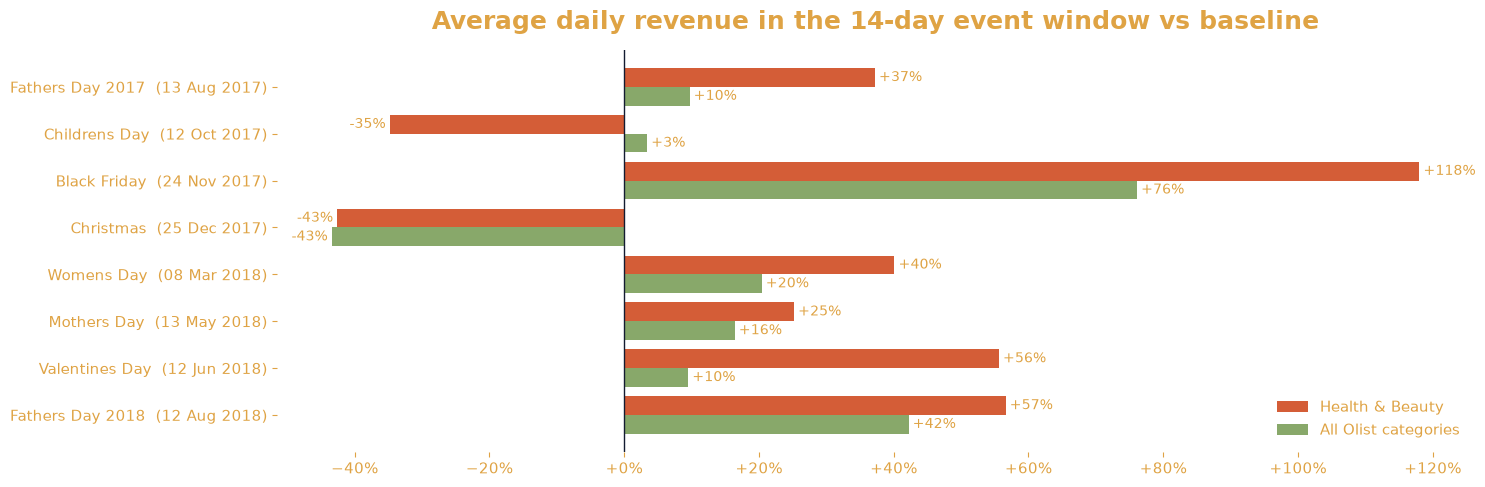

In [24]:
# Impact of marketing days on Health & Beauty
# Load the event results
events = sql.load_sql_to_df(QUERIES_DIR / "SQL Marketing Events vs Baseline.sql", engine)
events["window_end"] = pd.to_datetime(events["window_end"])
events = events.sort_values("window_end").reset_index(drop=True)
events["label"] = events["event_name"] + "  (" + events["window_end"].dt.strftime("%d %b %Y") + ")"


events[["event_name", "window_end", "base_days", "hb_uplift_pct", "platform_uplift_pct", "hb_vs_platform_pp"]]


# Health & Beauty uplift vs the whole platform
# If both bars are similar, the rise is platform-wide (growth or a general sales event).
# If the Health & Beauty bar is clearly longer, the event helped this category specifically.
y = np.arange(len(events))
height = 0.4

fig, ax = plt.subplots()
bars_hb = ax.barh(y - height / 2, events["hb_uplift_pct"], height,
                  color=OLIST_COLORS["coral_orange"], label=TARGET)
bars_pf = ax.barh(y + height / 2, events["platform_uplift_pct"], height,
                  color=OLIST_COLORS["sage_green"], label="All Olist categories")
ax.bar_label(bars_hb, fmt="%+.0f%%", padding=3, fontsize=10, color = OLIST_COLORS["gold"] )
ax.bar_label(bars_pf, fmt="%+.0f%%", padding=3, fontsize=10, color = OLIST_COLORS["gold"])
ax.axvline(0, color=OLIST_COLORS["dark_navy"], linewidth=1)
#ax.margins(x=0.1)                                   # room for the value labels
ax.set_yticks(y, labels=events["label"])
ax.invert_yaxis()                                   # first event at the top
ax.xaxis.set_major_formatter("{x:+.0f}%")
ax.set_title("Average daily revenue in the 14-day event window vs baseline")
ax.legend(loc="lower right", labelcolor = OLIST_COLORS["gold"])
fig.tight_layout()
clean.save_chart(fig, ASSETS_DIR / "event_uplift_vs_platform.png")
plt.show()



In [ ]:
# %% 4. Summary table with a plain-English verdict
# Cut-offs are a starting point: change them to suit your data, and state them in the report.
conditions = [
    events["hb_vs_platform_pp"] >= 20,
    events["hb_vs_platform_pp"] >= 5,
    events["hb_vs_platform_pp"] > -5,
]
choices = ["Strong category effect", "Moderate category effect", "In line with platform"]
events["verdict"] = np.select(conditions, choices, default="Weaker than platform")

summary = events[["event_name", "window_end", "hb_uplift_pct", "platform_uplift_pct",
                  "hb_vs_platform_pp", "hb_orders_uplift_pct", "hb_extra_revenue",
                  "verdict", "thin_baseline"]].copy()
summary["window_end"] = summary["window_end"].dt.strftime("%d %b %Y")
summary.columns = ["Event", "Date", "H&B uplift %", "Platform uplift %", "H&B vs platform (pp)",
                   "Orders uplift %", "Extra revenue (R$)", "Verdict", "Thin baseline"]

display(
    summary.style
    .format({"H&B uplift %": "{:+.0f}", "Platform uplift %": "{:+.0f}", "H&B vs platform (pp)": "{:+.0f}",
             "Orders uplift %": "{:+.0f}", "Extra revenue (R$)": "{:+,.0f}"}, na_rep="-")
    .background_gradient(subset=["H&B vs platform (pp)"], cmap="RdYlGn", vmin=-40, vmax=40)
    .hide(axis="index")
)

# Markdown version for the README (needs: pip install tabulate)
print(summary.round(0).to_markdown(index=False))